# NeoJaundice: complete project notebook (single dataset)

**Paper:** leakage-free evaluation, within-dataset shift, skin-tone/lighting audit, mitigations and screening metrics for newborn jaundice screening from photos.
*Retrospective research study only. This is not a diagnostic tool.*

**How to use**
1. Runtime > Change runtime type > **T4 GPU**.
2. Run cells top to bottom (Runtime > Run all also works).
3. Every result is saved to Drive (`MyDrive/jaundice_project/` and `.../results/`). Finished steps are **skipped automatically** on re-run, so if Colab disconnects, just run again from the top.

**Sections**
| Cell | What it does |
|---|---|
| 1-5 | Setup, data table (labels, duplicate groups, folds), image cache, dataset overview |
| 6 | Phase 2: color-feature baselines |
| 7-8 | Phase 3: EfficientNet-B0, 3 seeds x grouped and naive 5-fold |
| 9 | C1: leakage gap with bootstrap CI |
| 10 | C3: skin tone / lighting / age / weight / gender audit + annotation sheet |
| 11 | C2: within-dataset shift generalization + fine-tune + AdaBN |
| 12 | C4: mitigations (gray-world, color augmentation) |
| 13 | C5: calibration, operating points, refer-to-lab |
| 14 | C6: metadata fusion and bilirubin regression |
| 15 | Final summary file + zip |
| 16 | Literature check, limitations, writing checklist |

Approximate GPU time on a T4 (first run): Phase 3 about 20 min, C2 about 6 min, C4 about 20 min, C6 about 3 min.

In [ ]:
# ===== CELL 2: METRIC HELPERS =====
def sens_at_spec(yy, p, spec=0.90):
    fpr, tpr, _ = roc_curve(yy, p)
    return float(tpr[fpr <= 1 - spec].max())

def spec_at_sens(yy, p, sens=0.90):
    fpr, tpr, _ = roc_curve(yy, p)
    return float(1 - fpr[tpr >= sens].min())

def boot_ci(fn, *arrs, B=1000, seed=0):
    # bootstrap over rows; pass INFANT-level arrays so resampling is by infant
    rng = np.random.default_rng(seed); v = []; n = len(arrs[0])
    for _ in range(B):
        i = rng.integers(0, n, n)
        if arrs[0][i].min() == arrs[0][i].max():
            continue
        v.append(fn(*[a[i] for a in arrs]))
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def auc_ci(yy, p, B=1000):
    return boot_ci(roc_auc_score, np.asarray(yy), np.asarray(p), B=B)

def paired_auc_diff_ci(yy, p_old, p_new, B=1000):
    f = lambda a, b, c: roc_auc_score(a, c) - roc_auc_score(a, b)
    return boot_ci(f, np.asarray(yy), np.asarray(p_old), np.asarray(p_new), B=B)

def ece(yy, pp, bins=10):
    idx = np.minimum((np.asarray(pp) * bins).astype(int), bins - 1)
    e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            e += m.mean() * abs(np.asarray(yy)[m].mean() - np.asarray(pp)[m].mean())
    return float(e)
print('helpers ready')

helpers ready


In [ ]:
# ===== CELL 3: DATA TABLE (labels, duplicate groups, folds) =====
DATA = BASE / 'data/neojaundice'
if not (NEO_DIR / 'images').exists():
    zips = list(DATA.rglob('*.zip'))
    assert zips, f'NeoJaundice not found in Drive: {DATA}'
    ex = DATA / 'extracted'; ex.mkdir(exist_ok=True)
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(ex)
    print('extracted', zips[0])
assert (NEO_DIR / 'images').exists() and (NEO_DIR / 'chd_jaundice_published_2.csv').exists(), 'unexpected NeoJaundice folder layout'

def ahash(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (16, 16), interpolation=cv2.INTER_AREA).astype(np.float32)
    return (g > g.mean()).astype(np.float32).ravel()

def build_table():
    rows = []
    for f in sorted((NEO_DIR / 'images').glob('*')):
        m = re.match(r'(\d+)-(\d+)', f.name)
        if f.suffix.lower() in ('.jpg', '.jpeg', '.png') and m:
            rows.append((str(f), int(m[1]), int(m[2])))
    t = pd.DataFrame(rows, columns=['image_path', 'patient_id', 'image_idx'])
    meta = pd.read_csv(NEO_DIR / 'chd_jaundice_published_2.csv').drop_duplicates('patient_id')
    meta = meta.rename(columns={'blood(mg/dL)': 'bilirubin', 'age(day)': 'age_day', 'Treatment': 'treatment_DO_NOT_USE'})
    t = t.merge(meta[['patient_id', 'gender', 'gestational_age', 'age_day', 'weight', 'bilirubin', 'treatment_DO_NOT_USE']],
                on='patient_id', how='left')
    t['label'] = (t.bilirubin > THR).astype(float)
    t.loc[t.bilirubin.isna() | (t.bilirubin < 1), 'label'] = np.nan   # possibly missing bilirubin -> unlabeled
    # exact duplicate photos under different patient IDs -> same group (hash distance 0)
    with ThreadPoolExecutor(16) as ex:
        Hh = np.stack(list(tqdm(ex.map(ahash, t.image_path), total=len(t), desc='hashing')))
    D = 256 - (Hh @ Hh.T + (1 - Hh) @ (1 - Hh).T)
    i, j = np.where(np.triu(D <= 0.5, k=1))
    pid = t.patient_id.values
    parent = {p: p for p in np.unique(pid)}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for a, b in zip(i, j):
        if pid[a] != pid[b]:
            parent[find(pid[a])] = find(pid[b])
    roots = [find(p) for p in pid]
    t['group_id'] = ['n_' + str(c) for c in pd.factorize(pd.Series(roots))[0]]
    t['dataset'] = 'neojaundice'
    lab = t[t.label.notna()]
    t['fold_group'] = np.nan; t['fold_naive'] = np.nan
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for k, (_, va) in enumerate(sg.split(lab, lab.label, lab.group_id)):
        t.loc[lab.index[va], 'fold_group'] = k
    sk = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for k, (_, va) in enumerate(sk.split(lab, lab.label)):
        t.loc[lab.index[va], 'fold_naive'] = k
    return t

HF = BASE / 'harmonized.csv'
if HF.exists():
    df_all = pd.read_csv(HF)
    df_all = df_all[df_all.dataset == 'neojaundice'].reset_index(drop=True)
    print('loaded existing harmonized.csv (NeoJaundice rows only)')
else:
    df_all = build_table()
    df_all.to_csv(HF, index=False)
    print('built harmonized.csv | patients', df_all.patient_id.nunique(), '-> groups', df_all.group_id.nunique(), '(expected 745 -> 741)')

neo = df_all[df_all.label.notna()].reset_index(drop=True)
neo['fold_group'] = neo.fold_group.astype(int); neo['fold_naive'] = neo.fold_naive.astype(int)
y = neo.label.values.astype(np.float32)

# integrity checks
leak = sum(neo[neo.fold_group == k].group_id.isin(set(neo[neo.fold_group != k].group_id)).sum() for k in range(5))
conf = int((neo.groupby('group_id').label.nunique() > 1).sum())
print(f'labeled images {len(neo)} | infants(groups) {neo.group_id.nunique()} | grouped-split leaked images: {leak} | groups with conflicting labels: {conf}')
assert leak == 0 and conf == 0

loaded existing harmonized.csv (NeoJaundice rows only)
labeled images 2223 | infants(groups) 737 | grouped-split leaked images: 0 | groups with conflicting labels: 0


In [ ]:
# ===== CELL 4: IMAGE CACHE (224x224, built once) =====
CF = BASE / 'neo_224.npy'
def load224(p):
    return cv2.cvtColor(cv2.resize(cv2.imread(p), (224, 224), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
if CF.exists():
    X = np.load(CF)
else:
    with ThreadPoolExecutor(16) as ex:
        X = np.stack(list(tqdm(ex.map(load224, neo.image_path), total=len(neo), desc='caching images')))
    np.save(CF, X)
assert len(X) == len(neo), 'image cache does not match table: delete neo_224.npy and re-run'
Xg = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(dev)   # whole dataset on GPU
yg = torch.from_numpy(y).to(dev)
print('images on GPU:', tuple(Xg.shape))

images on GPU: (2223, 3, 224, 224)


images: 2223 labeled (+12 unlabeled/excluded) | infants: 737 | positive: 308 | negative: 429
sex: {'M': 400, 'F': 337}
         count    mean    std     min     25%     50%     75%     max
age_day  735.0     6.6    5.7     0.1     2.5     5.0     9.0    34.0
ga       737.0    38.3    1.8    30.0    37.0    39.0    40.0    42.0
weight   737.0  3163.2  525.9  1690.0  2810.0  3180.0  3500.0  5290.0
bili     737.0    11.3    5.2     1.1     7.5    11.8    15.1    25.7

grouped folds:
            images  infants  pos_rate
fold_group                           
0              450      148     0.413
1              441      147     0.408
2              444      147     0.473
3              444      147     0.365
4              444      148     0.439


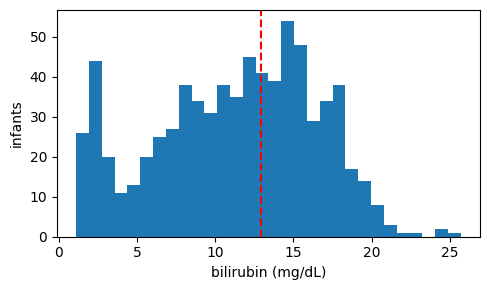

In [ ]:
# ===== CELL 5: DATASET OVERVIEW (Table 1) =====
G0 = neo.groupby('group_id').agg(y=('label', 'first'), age_day=('age_day', 'first'), ga=('gestational_age', 'first'),
                                  weight=('weight', 'first'), bili=('bilirubin', 'first'), gender=('gender', 'first'))
n_unl = int(df_all.label.isna().sum())
print(f'images: {len(neo)} labeled (+{n_unl} unlabeled/excluded) | infants: {len(G0)} | positive: {int(G0.y.sum())} | negative: {int((1 - G0.y).sum())}')
print(f'sex: {G0.gender.value_counts().to_dict()}')
T1 = G0[['age_day', 'ga', 'weight', 'bili']].describe().round(1).T
print(T1.to_string())
T1.to_csv(OUT / 'table1_dataset.csv')
ft = neo.groupby('fold_group').agg(images=('label', 'size'), infants=('group_id', 'nunique'), pos_rate=('label', 'mean')).round(3)
print('\ngrouped folds:'); print(ft.to_string()); ft.to_csv(OUT / 'table1_folds.csv')
plt.figure(figsize=(5, 3)); plt.hist(G0.bili.dropna(), bins=30); plt.axvline(THR, color='r', ls='--')
plt.xlabel('bilirubin (mg/dL)'); plt.ylabel('infants'); plt.tight_layout(); plt.savefig(OUT / 'fig_bilirubin_hist.png', dpi=120); plt.show()

In [ ]:
# ===== CELL 6: PHASE 2 - COLOR-FEATURE BASELINES (CPU, ~1-2 min) =====
def extract(im):
    im = cv2.resize(im, (128, 128), interpolation=cv2.INTER_AREA)          # im is RGB uint8
    ycc = cv2.cvtColor(im, cv2.COLOR_RGB2YCrCb)
    mask = (ycc[..., 1] >= 133) & (ycc[..., 1] <= 173) & (ycc[..., 2] >= 77) & (ycc[..., 2] <= 127)
    out = {'skin_frac': float(mask.mean())}
    if mask.mean() < 0.05:
        mask = np.ones_like(mask)
    f = im.astype(np.float32)
    gw = np.clip(f * (f.mean() / f.reshape(-1, 3).mean(0)), 0, 255).astype(np.uint8)   # gray-world
    for tag, a in [('raw', im), ('gw', gw)]:
        spaces = {'rgb': a, 'hsv': cv2.cvtColor(a, cv2.COLOR_RGB2HSV), 'lab': cv2.cvtColor(a, cv2.COLOR_RGB2LAB), 'ycc': cv2.cvtColor(a, cv2.COLOR_RGB2YCrCb)}
        for s, arr in spaces.items():
            px = arr[mask].astype(np.float32) / 255
            mean, std, med = px.mean(0), px.std(0), np.median(px, 0)
            for c in range(3):
                out[f'{tag}_{s}{c}_mean'] = mean[c]; out[f'{tag}_{s}{c}_std'] = std[c]; out[f'{tag}_{s}{c}_med'] = med[c]
    return out

FF = BASE / 'features_neo_v2.csv'
if FF.exists():
    F = pd.read_csv(FF)
else:
    with ThreadPoolExecutor(8) as ex:
        F = pd.DataFrame(list(tqdm(ex.map(extract, list(X)), total=len(X), desc='features')))
    F.to_csv(FF, index=False)
assert len(F) == len(neo)
print('skin_frac min/median/max:', round(float(F.skin_frac.min()), 3), round(float(F.skin_frac.median()), 3), round(float(F.skin_frac.max()), 3))

models = {
    'logreg': lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'rf': lambda: RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'hgb': lambda: HistGradientBoostingClassifier(random_state=42),
}
res = []
for split in ['fold_group', 'fold_naive']:
    for tag in ['raw', 'gw']:
        Xf = F[[c for c in F.columns if c.startswith(tag + '_')]].values
        for mname, mk in models.items():
            oof = np.zeros(len(neo)); aucs = []
            for k in range(5):
                tr = (neo[split] != k).values; va = ~tr
                m = mk().fit(Xf[tr], y[tr]); oof[va] = m.predict_proba(Xf[va])[:, 1]
                aucs.append(roc_auc_score(y[va], oof[va]))
            g = pd.DataFrame({'g': neo.group_id, 'y': y, 'p': oof}).groupby('g').agg(y=('y', 'first'), p=('p', 'mean'))
            res.append(dict(split=split, norm=tag, model=mname, img_auc=f'{np.mean(aucs):.3f}+-{np.std(aucs):.3f}',
                            infant_auc=round(roc_auc_score(g.y, g.p), 3), sens_at_90spec=round(sens_at_spec(g.y, g.p), 3)))
R2 = pd.DataFrame(res); print(R2.to_string(index=False)); R2.to_csv(OUT / 'phase2_baselines.csv', index=False)
print('note: gray-world is used as a proxy for calibration-card normalization (card detection is not implemented)')

skin_frac min/median/max: 0.132 0.256 0.553
     split norm  model      img_auc  infant_auc  sens_at_90spec
fold_group  raw logreg 0.835+-0.015       0.883           0.601
fold_group  raw     rf 0.817+-0.021       0.867           0.588
fold_group  raw    hgb 0.807+-0.023       0.856           0.542
fold_group   gw logreg 0.848+-0.020       0.886           0.597
fold_group   gw     rf 0.838+-0.018       0.882           0.620
fold_group   gw    hgb 0.824+-0.022       0.865           0.571
fold_naive  raw logreg 0.837+-0.004       0.883           0.614
fold_naive  raw     rf 0.826+-0.017       0.878           0.597
fold_naive  raw    hgb 0.822+-0.022       0.876           0.594
fold_naive   gw logreg 0.848+-0.005       0.885           0.617
fold_naive   gw     rf 0.850+-0.010       0.892           0.627
fold_naive   gw    hgb 0.837+-0.010       0.878           0.617
note: gray-world is used as a proxy for calibration-card normalization (card detection is not implemented)


In [ ]:
# ===== CELL 7: DEEP-LEARNING HELPERS (run again after any restart) =====
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def gw_norm(xb):
    m_all = xb.mean(dim=(1, 2, 3), keepdim=True)
    m_ch = xb.mean(dim=(2, 3), keepdim=True).clamp(min=1e-4)
    return (xb * (m_all / m_ch)).clamp(0, 1)

def prep(xb, train=False, color=False, norm=None):
    xb = xb.float().div_(255)
    if train:
        if np.random.rand() < 0.5: xb = xb.flip(3)
        if np.random.rand() < 0.5: xb = xb.flip(2)
        if color:
            n = xb.shape[0]
            bright = torch.empty(n, 1, 1, 1, device=xb.device).uniform_(0.8, 1.2)
            gain = torch.empty(n, 3, 1, 1, device=xb.device).uniform_(0.9, 1.1)
            xb = (xb * bright * gain).clamp(0, 1)
    if norm is not None:
        xb = norm(xb)
    return ((xb - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def make_model():
    m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    m.classifier[1] = nn.Linear(1280, 1)
    return m.to(dev).to(memory_format=torch.channels_last)

def train_model(tr_idx, seed=0, epochs=EPOCHS, lr=LR, color=False, norm=None, model=None, target=None):
    # target=None -> classification (BCE on labels y); target=GPU tensor -> regression (MSE)
    torch.manual_seed(seed); np.random.seed(seed)
    tr = torch.as_tensor(np.asarray(tr_idx), device=dev); n = len(tr)
    m = model if model is not None else make_model()
    tg = yg if target is None else target
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(n / BS)))
    scaler = torch.amp.GradScaler()
    for ep in range(epochs):
        m.train(); perm = tr[torch.randperm(n, device=dev)]
        for i in range(0, n, BS):
            idx = perm[i:i + BS]
            if len(idx) < 2:
                sch.step(); continue
            with torch.autocast('cuda', dtype=torch.float16):
                out = m(prep(Xg[idx], True, color, norm)).squeeze(1)
            out = out.float()
            loss = Fnn.binary_cross_entropy_with_logits(out, tg[idx]) if target is None else Fnn.mse_loss(out, tg[idx])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
    return m

def predict(m, idx, norm=None, reg=False):
    m.eval(); out = []
    idx = torch.as_tensor(np.asarray(idx), device=dev)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in range(0, len(idx), 256):
            o = m(prep(Xg[idx[i:i + 256]], False, False, norm)).squeeze(1).float()
            out.append((o if reg else torch.sigmoid(o)).cpu().numpy())
    return np.concatenate(out)

def adabn(m, idx, norm=None):
    # simple domain adaptation: re-estimate BatchNorm statistics on UNLABELED target images
    m2 = copy.deepcopy(m)
    for mod in m2.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats(); mod.momentum = None
    m2.train()
    for mod in m2.modules():
        if isinstance(mod, nn.Dropout):
            mod.eval()
    idx = torch.as_tensor(np.asarray(idx), device=dev)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for i in range(0, len(idx), 128):
            m2(prep(Xg[idx[i:i + 128]], False, False, norm))
    m2.eval(); return m2

def oof_path(split, seed, tag=''):
    return BASE / (f'oof_effb0{tag}_{split}' + ('' if (seed == 0 and tag == '') else f'_s{seed}') + '.npy')

def cv_oof(split, seed, tag='', **kw):
    f = oof_path(split, seed, tag)
    if f.exists():
        return np.load(f)
    oof = np.zeros(len(neo))
    for k in range(5):
        tr = np.where(neo[split] != k)[0]; va = np.where(neo[split] == k)[0]
        m = train_model(tr, seed=seed, **kw)
        oof[va] = predict(m, va, norm=kw.get('norm'))
        print(f'  {split}{tag} seed {seed} fold {k}: img AUROC {roc_auc_score(y[va], oof[va]):.3f}', flush=True)
    np.save(f, oof); return oof

def inf_tab(idx, p):
    return pd.DataFrame({'g': neo.group_id.values[idx], 'y': y[idx], 'p': p}).groupby('g').agg(y=('y', 'first'), p=('p', 'mean'))

def inf_auc(idx, p):
    t = inf_tab(idx, p)
    return float(roc_auc_score(t.y, t.p)) if t.y.nunique() == 2 else float('nan')

ALL = np.arange(len(neo))

def audit_stats():
    f = OUT / 'audit_stats.npy'
    if f.exists():
        a = np.load(f)
        if len(a) == len(neo): return a
    rows = []
    for i in range(len(neo)):
        crop = X[i, 78:146, 78:146, :].astype(np.float32) / 255       # central skin window (approximate)
        lab = cv2.cvtColor(crop, cv2.COLOR_RGB2LAB).reshape(-1, 3)
        L, b = float(np.median(lab[:, 0])), float(np.median(lab[:, 2]))
        ita = float(np.degrees(np.arctan((L - 50) / b)))
        full = float(cv2.cvtColor(X[i].astype(np.float32) / 255, cv2.COLOR_RGB2LAB)[..., 0].mean())   # whole-image brightness
        rows.append((ita, full, L, b))
    a = np.array(rows); np.save(f, a); return a

def make_G():
    a = audit_stats()
    P = np.mean([np.load(oof_path('fold_group', s)) for s in range(N_SEEDS)], axis=0)
    d = neo.assign(ita=a[:, 0], light=a[:, 1], p=P)
    G = d.groupby('group_id').agg(y=('label', 'first'), ita=('ita', 'median'), light=('light', 'median'), age_day=('age_day', 'first'),
                                   ga=('gestational_age', 'first'), weight=('weight', 'first'), gender=('gender', 'first'),
                                   bili=('bilirubin', 'first'), fold=('fold_group', 'first'), p=('p', 'mean'))
    G['male'] = (G.gender == 'M').astype(float)
    return G, P
print('deep helpers ready')

deep helpers ready


In [ ]:
# ===== CELL 8: PHASE 3 - EfficientNet-B0, grouped + naive 5-fold, N_SEEDS seeds =====
t0 = time.time()
for split in ['fold_group', 'fold_naive']:
    for seed in range(N_SEEDS):
        cv_oof(split, seed)
    print(f'{split} ready ({time.time() - t0:.0f}s)', flush=True)

def summarize(oofs, split):
    ens = np.mean(oofs, axis=0)
    per_seed = [roc_auc_score(*inf_tab(ALL, o)[['y', 'p']].values.T) for o in oofs]
    fold_aucs = [roc_auc_score(y[(neo[split] == k).values], ens[(neo[split] == k).values]) for k in range(5)]
    t = inf_tab(ALL, ens)
    lo, hi = auc_ci(t.y.values, t.p.values)
    return dict(split=split, img_auc_ens=f'{np.mean(fold_aucs):.3f}+-{np.std(fold_aucs):.3f}',
                infant_auc_per_seed=str(np.round(per_seed, 3).tolist()), infant_auc_ens=round(roc_auc_score(t.y, t.p), 3),
                infant_auc_ci=f'[{lo:.3f},{hi:.3f}]', sens_at_90spec=round(sens_at_spec(t.y, t.p), 3),
                spec_at_90sens=round(spec_at_sens(t.y, t.p), 3))
R3 = pd.DataFrame([summarize([np.load(oof_path(s, sd)) for sd in range(N_SEEDS)], s) for s in ['fold_group', 'fold_naive']])
print(R3.to_string(index=False)); R3.to_csv(OUT / 'phase3_effb0.csv', index=False)

fold_group ready (3s)
fold_naive ready (5s)
     split  img_auc_ens   infant_auc_per_seed  infant_auc_ens infant_auc_ci  sens_at_90spec  spec_at_90sens
fold_group 0.891+-0.008 [0.918, 0.918, 0.917]           0.922 [0.904,0.939]           0.734           0.795
fold_naive 0.906+-0.009  [0.93, 0.936, 0.932]           0.936 [0.918,0.951]           0.818           0.851


                  split  infant_auc     lo     hi
grouped (patient-level)      0.9215 0.9032 0.9389
    naive (image-level)      0.9356 0.9191 0.9509
    gap naive - grouped      0.0141 0.0073 0.0211
per-seed gaps: [0.012  0.0183 0.0147] | gap CI excludes 0: True
naive split: 2139/2223 validation images (96%) have a same-infant image in training


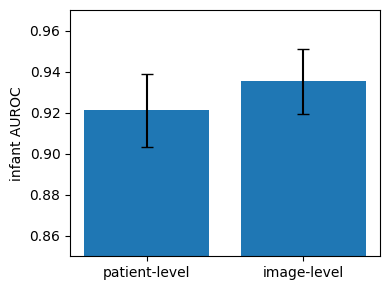

In [ ]:
# ===== CELL 9: C1 - LEAKAGE GAP (naive image-level split vs patient-level split) =====
tg_ = inf_tab(ALL, np.mean([np.load(oof_path('fold_group', s)) for s in range(N_SEEDS)], axis=0))
tn_ = inf_tab(ALL, np.mean([np.load(oof_path('fold_naive', s)) for s in range(N_SEEDS)], axis=0))
yy, pg, pn = tg_.y.values, tg_.p.values, tn_.p.values
rng = np.random.default_rng(0); ag, an, d = [], [], []
for _ in range(2000):
    i = rng.integers(0, len(yy), len(yy))
    if yy[i].min() == yy[i].max(): continue
    a, b = roc_auc_score(yy[i], pg[i]), roc_auc_score(yy[i], pn[i]); ag.append(a); an.append(b); d.append(b - a)
ci = lambda v: (float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
seed_gaps = [roc_auc_score(*inf_tab(ALL, np.load(oof_path('fold_naive', s)))[['y', 'p']].values.T) -
             roc_auc_score(*inf_tab(ALL, np.load(oof_path('fold_group', s)))[['y', 'p']].values.T) for s in range(N_SEEDS)]
C1 = pd.DataFrame([dict(split='grouped (patient-level)', infant_auc=ci(ag)[0], lo=ci(ag)[1], hi=ci(ag)[2]),
                   dict(split='naive (image-level)', infant_auc=ci(an)[0], lo=ci(an)[1], hi=ci(an)[2]),
                   dict(split='gap naive - grouped', infant_auc=ci(d)[0], lo=ci(d)[1], hi=ci(d)[2])]).round(4)
print(C1.to_string(index=False))
print('per-seed gaps:', np.round(seed_gaps, 4), '| gap CI excludes 0:', bool(np.percentile(d, 2.5) > 0))
nv = neo.copy(); tot = leak_n = 0
for k in range(5):
    va = nv[nv.fold_naive == k]; tr = nv[nv.fold_naive != k]
    leak_n += va.group_id.isin(set(tr.group_id)).sum(); tot += len(va)
print(f'naive split: {leak_n}/{tot} validation images ({100 * leak_n / tot:.0f}%) have a same-infant image in training')
C1.to_csv(OUT / 'c1_leakage.csv', index=False)
plt.figure(figsize=(4, 3)); plt.bar(['patient-level', 'image-level'], [ci(ag)[0], ci(an)[0]],
                                    yerr=[[ci(ag)[0] - ci(ag)[1], ci(an)[0] - ci(an)[1]], [ci(ag)[2] - ci(ag)[0], ci(an)[2] - ci(an)[0]]], capsize=4)
plt.ylim(0.85, 0.97); plt.ylabel('infant AUROC'); plt.tight_layout(); plt.savefig(OUT / 'fig_c1_leakage.png', dpi=120); plt.show()

infants 737 | corr(ITA,label)=-0.083 | corr(ITA,bilirubin)=-0.102 | ITA range -53.1..38.7
caveat: jaundice itself changes skin color, so ITA is partly confounded with the label; the crop window is approximate
            factor level   n  pos_rate          range   auc        auc_ci  sens_at_global_thr  spec_at_global_thr
   skin tone (ITA)   low 246     0.463     -53.1..6.0 0.905 [0.864,0.942]               0.754               0.871
   skin tone (ITA)   mid 245     0.494      6.0..13.8 0.894 [0.852,0.932]               0.744               0.855
   skin tone (ITA)  high 246     0.297     13.8..38.7 0.953 [0.925,0.976]               0.685               0.965
lighting (image L)   low 246     0.427     36.4..50.8 0.915 [0.879,0.950]               0.695               0.901
lighting (image L)   mid 245     0.437     50.9..53.3 0.932 [0.902,0.961]               0.785               0.920
lighting (image L)  high 246     0.390     53.3..61.2 0.920 [0.885,0.953]               0.719              

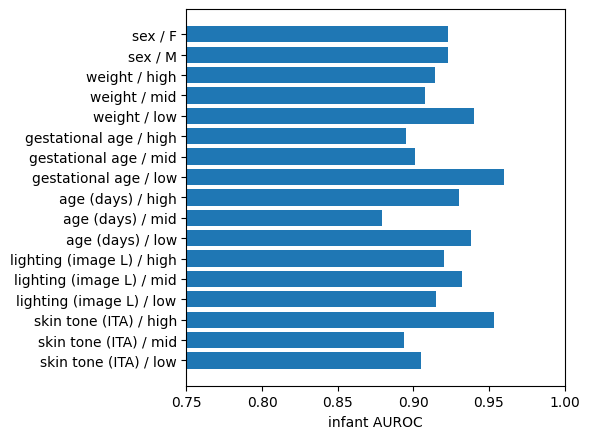

To use manual labels: fill manual_tone in annotation_sheet.csv, save as annotation_filled.csv in the same Drive folder, re-run this cell.


In [ ]:
# ===== CELL 10: C3 - SKIN TONE / LIGHTING / OTHER SUBGROUP AUDIT =====
G, P = make_G()
print(f'infants {len(G)} | corr(ITA,label)={np.corrcoef(G.ita, G.y)[0, 1]:.3f} | corr(ITA,bilirubin)={np.corrcoef(G.ita, G.bili.fillna(G.bili.median()))[0, 1]:.3f}'
      f' | ITA range {G.ita.min():.1f}..{G.ita.max():.1f}')
print('caveat: jaundice itself changes skin color, so ITA is partly confounded with the label; the crop window is approximate')
fpr, tpr, th = roc_curve(G.y, G.p); GTHR = float(th[np.where(fpr <= 0.10)[0][-1]])   # one global threshold (90% spec overall)

def terc(v):
    v = v.astype(float); v = v.fillna(v.median())
    return pd.qcut(v.rank(method='first'), 3, labels=['low', 'mid', 'high'])

def sub_row(factor, level, s, rng_txt=''):
    d = {'factor': factor, 'level': level, 'n': len(s), 'pos_rate': round(float(s.y.mean()), 3), 'range': rng_txt}
    if s.y.nunique() == 2:
        lo, hi = auc_ci(s.y.values, s.p.values)
        d.update(auc=round(float(roc_auc_score(s.y, s.p)), 3), auc_ci=f'[{lo:.3f},{hi:.3f}]')
    else:
        d.update(auc=np.nan, auc_ci='')
    pr = s.p.values >= GTHR
    d['sens_at_global_thr'] = round(float(pr[s.y.values == 1].mean()), 3) if (s.y == 1).any() else np.nan
    d['spec_at_global_thr'] = round(float((~pr[s.y.values == 0]).mean()), 3) if (s.y == 0).any() else np.nan
    return d

rows = []
for name, col in {'skin tone (ITA)': 'ita', 'lighting (image L)': 'light', 'age (days)': 'age_day', 'gestational age': 'ga', 'weight': 'weight'}.items():
    b = terc(G[col])
    for lv in ['low', 'mid', 'high']:
        s = G[b == lv]; rows.append(sub_row(name, lv, s, f'{s[col].min():.1f}..{s[col].max():.1f}'))
for gname in ['M', 'F']:
    rows.append(sub_row('sex', gname, G[G.gender == gname]))
C3 = pd.DataFrame(rows); print(C3.to_string(index=False)); C3.to_csv(OUT / 'c3_subgroups.csv', index=False)

d = C3.dropna(subset=['auc']); plt.figure(figsize=(6, 4.5))
plt.barh(d.factor + ' / ' + d.level.astype(str), d.auc); plt.xlim(0.75, 1.0); plt.xlabel('infant AUROC'); plt.tight_layout()
plt.savefig(OUT / 'fig_c3_subgroups.png', dpi=120); plt.show()

# ---- hand-annotation sheet (~120 infants): view pages, fill manual_tone (1=lightest ... 10=darkest, Monk scale) ----
rs = np.random.default_rng(0)
sel = rs.choice(G.index.values, size=min(120, len(G)), replace=False)
first = neo.reset_index().groupby('group_id')['index'].first()
sheet = pd.DataFrame({'id': range(len(sel)), 'group_id': sel, 'image_path': [neo.image_path[first[g]] for g in sel],
                      'ita_auto': [round(float(G.ita[g]), 1) for g in sel], 'manual_tone': np.nan})
if not (BASE / 'annotation_sheet.csv').exists():
    sheet.to_csv(BASE / 'annotation_sheet.csv', index=False)
    pg_dir = BASE / 'annotation_pages'; pg_dir.mkdir(exist_ok=True)
    for pgi in range(0, len(sheet), 20):
        fig, ax = plt.subplots(4, 5, figsize=(15, 12))
        for a_, r in zip(ax.ravel(), sheet.iloc[pgi:pgi + 20].itertuples()):
            a_.imshow(X[first[r.group_id]]); a_.set_title(f'id {r.id}', fontsize=11); a_.axis('off')
        plt.tight_layout(); plt.savefig(pg_dir / f'page_{pgi // 20 + 1}.png', dpi=70); plt.close()
    print('annotation sheet + page images saved to Drive: annotation_sheet.csv, annotation_pages/')
AF = BASE / 'annotation_filled.csv'
if AF.exists():
    A = pd.read_csv(AF).dropna(subset=['manual_tone'])
    rho, pv = spearmanr(A.manual_tone, A.ita_auto)
    print(f'manual vs auto tone: n={len(A)}, Spearman rho={rho:.3f} (expected NEGATIVE: darker skin = lower ITA), p={pv:.3g}')
else:
    print('To use manual labels: fill manual_tone in annotation_sheet.csv, save as annotation_filled.csv in the same Drive folder, re-run this cell.')

In [ ]:
# ===== CELL 11: C2 - WITHIN-DATASET SHIFT (train on 2 tertiles, test on the held-out extreme tertile) =====
G, P = make_G()
P0 = np.load(oof_path('fold_group', 0))          # single-seed in-distribution reference
G['random'] = np.random.default_rng(7).random(len(G))   # control: random shift with the same training size
FACTORS = ['ita', 'light', 'age_day', 'random']
def tercile_int(factor):
    v = G[factor].astype(float); v = v.fillna(v.median())
    return pd.qcut(v.rank(method='first'), 3, labels=[0, 1, 2]).astype(int)
BINS = {f: tercile_int(f) for f in FACTORS}
NAMES = ['low', 'mid', 'high']

SP_F = OUT / 'shift_preds.pkl'
SP = pickle.load(open(SP_F, 'rb')) if SP_F.exists() else {}
def split_idx(factor, held):
    hg = set(BINS[factor].index[BINS[factor] == held])
    is_held = neo.group_id.isin(hg).values
    return np.where(~is_held)[0], np.where(is_held)[0]

def run_scenario(factor, held, cfg_name, cfg, extras=False):
    key = f'{factor}|{held}|{cfg_name}'
    if key in SP and (not extras or 'adabn' in SP[key]):
        return SP[key]
    tr, te = split_idx(factor, held)
    m = train_model(tr, seed=0, **cfg)
    res = {'te': te, 'plain': predict(m, te, norm=cfg.get('norm'))}
    if extras:
        res['adabn'] = predict(adabn(m, te, norm=cfg.get('norm')), te, norm=cfg.get('norm'))
        hg = np.array(sorted(set(neo.group_id.values[te])))
        ftg = set(np.random.default_rng(11).choice(hg, size=max(3, int(0.15 * len(hg))), replace=False))   # 15% of target infants
        is_ft = np.array([g in ftg for g in neo.group_id.values[te]])
        m3 = train_model(te[is_ft], seed=0, epochs=5, lr=1e-4, model=copy.deepcopy(m), **cfg)
        res['rest_mask'] = ~is_ft; res['ft_rest'] = te[~is_ft]; res['ft'] = predict(m3, te[~is_ft], norm=cfg.get('norm'))
    SP[key] = res; pickle.dump(SP, open(SP_F, 'wb'))
    return res

rows = []
for f in FACTORS:
    for held in [0, 2]:
        r = run_scenario(f, held, 'base', {}, extras=True); te = r['te']
        t = inf_tab(te, r['plain']); lo, hi = auc_ci(t.y.values, t.p.values)
        ref = inf_auc(te, P0[te]); sh = float(roc_auc_score(t.y, t.p)); rest = r['rest_mask']
        rows.append(dict(factor=f, held_out=NAMES[held], infants=len(t), pos_rate=round(float(t.y.mean()), 3), in_dist_auc=round(ref, 3),
                         shift_auc=round(sh, 3), shift_ci=f'[{lo:.3f},{hi:.3f}]', drop=round(ref - sh, 3), adabn_auc=round(inf_auc(te, r['adabn']), 3),
                         rest_plain_auc=round(inf_auc(r['ft_rest'], r['plain'][rest]), 3), rest_finetune_auc=round(inf_auc(r['ft_rest'], r['ft']), 3)))
    print(f'{f} done', flush=True)
C2 = pd.DataFrame(rows); print(C2.to_string(index=False)); C2.to_csv(OUT / 'c2_shift.csv', index=False)
print('\nmean AUROC drop by factor (the "random" row controls for the smaller training set):')
print(C2.groupby('factor')['drop'].mean().round(3).to_string())
print('note: rest_* columns compare plain vs fine-tuned (on 15% of target infants) evaluated on the SAME remaining target infants')

ita done
light done
age_day done
random done
 factor held_out  infants  pos_rate  in_dist_auc  shift_auc      shift_ci  drop  adabn_auc  rest_plain_auc  rest_finetune_auc
    ita      low      246     0.463        0.902      0.883 [0.837,0.925] 0.019      0.881           0.891              0.904
    ita     high      246     0.297        0.951      0.946 [0.915,0.970] 0.006      0.941           0.937              0.934
  light      low      246     0.427        0.910      0.907 [0.866,0.945] 0.003      0.906           0.909              0.913
  light     high      246     0.390        0.916      0.908 [0.871,0.943] 0.008      0.905           0.909              0.902
age_day      low      246     0.252        0.937      0.916 [0.880,0.949] 0.021      0.919           0.919              0.931
age_day     high      246     0.386        0.925      0.890 [0.850,0.926] 0.035      0.885           0.883              0.891
 random      low      246     0.463        0.912      0.909 [0.872,0.945]

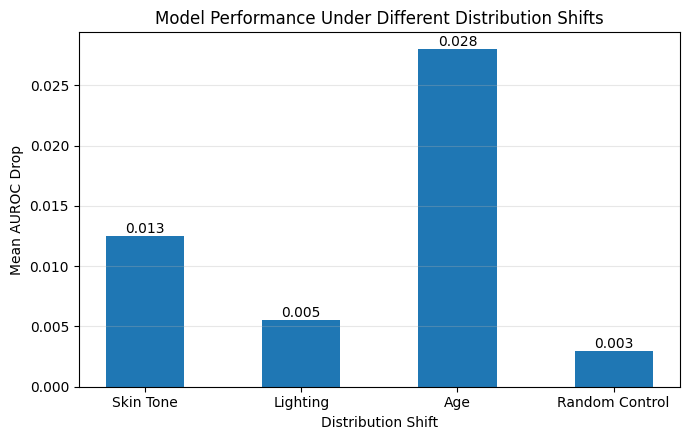

In [ ]:
# ===== CELL 12: Model Performance Under Distribution Shifts: =====
import matplotlib.pyplot as plt

shift_drop = C2.groupby('factor')['drop'].mean()

labels = ['Skin Tone', 'Lighting', 'Age', 'Random Control']
values = [
    shift_drop['ita'],
    shift_drop['light'],
    shift_drop['age_day'],
    shift_drop['random']
]

plt.figure(figsize=(7, 4.5))

bars = plt.bar(labels, values, width=0.5)

plt.xlabel('Distribution Shift')
plt.ylabel('Mean AUROC Drop')
plt.title('Model Performance Under Different Distribution Shifts')

plt.grid(axis='y', alpha=0.3)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [ ]:
# ===== CELL 13: C4 - MITIGATIONS (gray-world normalization, color augmentation, AdaBN, fine-tune from C2) =====
MIT = {'gw': dict(norm=gw_norm), 'color': dict(color=True), 'gw_color': dict(norm=gw_norm, color=True)}

# (a) under shift
rows = []
for f in FACTORS:
    for held in [0, 2]:
        rb = run_scenario(f, held, 'base', {}, extras=True)
        row = {'scenario': f'{f}|{NAMES[held]}', 'base': inf_auc(rb['te'], rb['plain']), 'base+adabn': inf_auc(rb['te'], rb['adabn'])}
        for name, cfg in MIT.items():
            r = run_scenario(f, held, name, cfg); row[name] = inf_auc(r['te'], r['plain'])
        rows.append(row)
    print(f'{f} done', flush=True)
C4s = pd.DataFrame(rows).set_index('scenario'); C4s.loc['MEAN'] = C4s.mean()
print(C4s.round(3).to_string()); C4s.round(4).to_csv(OUT / 'c4_shift.csv')

# (b) in-distribution grouped 5-fold (seed 0), paired bootstrap vs baseline
P0 = np.load(oof_path('fold_group', 0)); tb = inf_tab(ALL, P0); rows = []
for name, cfg in MIT.items():
    o = cv_oof('fold_group', 0, tag='_' + name, **cfg); tn = inf_tab(ALL, o)
    lo, hi = paired_auc_diff_ci(tb.y.values, tb.p.values, tn.p.values)
    rows.append(dict(method=name, infant_auc=round(float(roc_auc_score(tn.y, tn.p)), 3), base_auc=round(float(roc_auc_score(tb.y, tb.p)), 3),
                     delta=round(float(roc_auc_score(tn.y, tn.p) - roc_auc_score(tb.y, tb.p)), 4), delta_ci=f'[{lo:.4f},{hi:.4f}]'))
C4c = pd.DataFrame(rows); print('\nin-distribution (grouped 5-fold):'); print(C4c.to_string(index=False)); C4c.to_csv(OUT / 'c4_cv.csv', index=False)
print('read: a delta whose CI includes 0 means the mitigation did not help detectably')

ita done
light done
age_day done
random done
               base  base+adabn     gw  color  gw_color
scenario                                               
ita|low       0.883       0.881  0.880  0.883     0.883
ita|high      0.946       0.941  0.939  0.949     0.946
light|low     0.907       0.906  0.906  0.898     0.902
light|high    0.908       0.905  0.907  0.906     0.904
age_day|low   0.916       0.919  0.925  0.932     0.924
age_day|high  0.890       0.885  0.887  0.904     0.896
random|low    0.909       0.910  0.911  0.910     0.916
random|high   0.919       0.917  0.919  0.913     0.906
MEAN          0.910       0.908  0.909  0.912     0.910

in-distribution (grouped 5-fold):
  method  infant_auc  base_auc   delta         delta_ci
      gw       0.916     0.918 -0.0012 [-0.0086,0.0059]
   color       0.919     0.918  0.0019 [-0.0061,0.0098]
gw_color       0.915     0.918 -0.0025 [-0.0109,0.0054]
read: a delta whose CI includes 0 means the mitigation did not help detectably


fold 0: temperature 1.54
fold 1: temperature 1.56
fold 2: temperature 1.56
fold 3: temperature 1.54
fold 4: temperature 1.47

ECE (10 bins), cross-fitted temperature scaling:
 level  before  after
 image  0.0583 0.0157
infant  0.0334 0.0730

cross-fitted operating points (threshold chosen on other folds):
    fixed  sens       sens_ci  spec       spec_ci
 spec=0.9 0.740 [0.688,0.786] 0.900 [0.869,0.928]
spec=0.95 0.571 [0.519,0.627] 0.944 [0.921,0.965]
 sens=0.9 0.896 [0.861,0.931] 0.814 [0.776,0.849]
sens=0.95 0.945 [0.918,0.969] 0.744 [0.703,0.782]

refer-to-lab (abstain on the least confident infants; descriptive, not a validated rule):
 coverage   n  sens  spec   acc
      1.0 737 0.792 0.865 0.834
      0.9 663 0.863 0.887 0.878
      0.8 590 0.893 0.913 0.905
      0.7 516 0.929 0.943 0.938
      0.6 442 0.943 0.960 0.955
      0.5 368 0.950 0.966 0.962


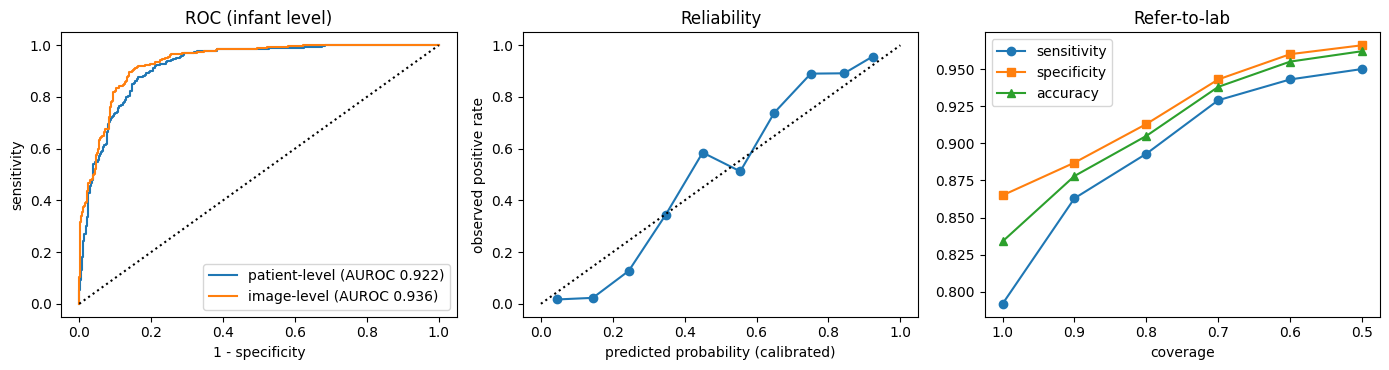

In [ ]:
# ===== CELL 14: C5 - SCREENING METRICS (calibration, operating points, refer-to-lab) =====
G, P = make_G()
z = logit(np.clip(P, 1e-4, 1 - 1e-4)); pc = np.zeros(len(P))
for k in range(5):
    tr = (neo.fold_group != k).values
    nll = lambda T: -np.mean(y[tr] * np.log(expit(z[tr] / T) + 1e-9) + (1 - y[tr]) * np.log(1 - expit(z[tr] / T) + 1e-9))
    T = minimize_scalar(nll, bounds=(0.1, 10), method='bounded').x
    pc[~tr] = expit(z[~tr] / T)
    print(f'fold {k}: temperature {T:.2f}')
gi = pd.DataFrame({'g': neo.group_id.values, 'y': y, 'p': pc}).groupby('g').agg(y=('y', 'first'), p=('p', 'mean'))
gi['fold'] = G.fold.loc[gi.index].values; gi['p_raw'] = G.p.loc[gi.index].values
E = pd.DataFrame([dict(level='image', before=ece(y, P), after=ece(y, pc)), dict(level='infant', before=ece(gi.y.values, gi.p_raw.values), after=ece(gi.y.values, gi.p.values))]).round(4)
print('\nECE (10 bins), cross-fitted temperature scaling:'); print(E.to_string(index=False)); E.to_csv(OUT / 'c5_ece.csv', index=False)

def crossfit(kind, target):
    pred = np.zeros(len(gi), bool)
    for k in range(5):
        tr = (gi.fold != k).values; te = ~tr
        if kind == 'spec':
            thr = np.quantile(gi.p.values[tr & (gi.y.values == 0)], target); pred[te] = gi.p.values[te] > thr
        else:
            thr = np.quantile(gi.p.values[tr & (gi.y.values == 1)], 1 - target); pred[te] = gi.p.values[te] >= thr
    return pred
rows = []
for kind, target in [('spec', 0.90), ('spec', 0.95), ('sens', 0.90), ('sens', 0.95)]:
    pred = crossfit(kind, target); yy = gi.y.values
    sens_f = lambda a, b: b[a == 1].mean(); spec_f = lambda a, b: (~b[a == 0]).mean()
    s_lo, s_hi = boot_ci(sens_f, yy, pred); c_lo, c_hi = boot_ci(spec_f, yy, pred)
    rows.append(dict(fixed=f'{kind}={target}', sens=round(float(sens_f(yy, pred)), 3), sens_ci=f'[{s_lo:.3f},{s_hi:.3f}]',
                     spec=round(float(spec_f(yy, pred)), 3), spec_ci=f'[{c_lo:.3f},{c_hi:.3f}]'))
C5 = pd.DataFrame(rows); print('\ncross-fitted operating points (threshold chosen on other folds):'); print(C5.to_string(index=False)); C5.to_csv(OUT / 'c5_operating.csv', index=False)

gs = gi.assign(conf=(gi.p - 0.5).abs()).sort_values('conf', ascending=False); rows = []
for cov in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    s = gs.iloc[:int(round(cov * len(gs)))]; pr = s.p >= 0.5
    rows.append(dict(coverage=cov, n=len(s), sens=round(float(pr[s.y == 1].mean()), 3), spec=round(float((~pr[s.y == 0]).mean()), 3), acc=round(float((pr == s.y).mean()), 3)))
RC = pd.DataFrame(rows); print('\nrefer-to-lab (abstain on the least confident infants; descriptive, not a validated rule):'); print(RC.to_string(index=False)); RC.to_csv(OUT / 'c5_risk_coverage.csv', index=False)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for split, lab_ in [('fold_group', 'patient-level'), ('fold_naive', 'image-level')]:
    t = inf_tab(ALL, np.mean([np.load(oof_path(split, s)) for s in range(N_SEEDS)], axis=0)); fp, tp, _ = roc_curve(t.y, t.p)
    ax[0].plot(fp, tp, label=f'{lab_} (AUROC {roc_auc_score(t.y, t.p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_xlabel('1 - specificity'); ax[0].set_ylabel('sensitivity'); ax[0].legend(); ax[0].set_title('ROC (infant level)')
bins_ = np.minimum((gi.p.values * 10).astype(int), 9); xs, ys = [], []
for b in range(10):
    m = bins_ == b
    if m.sum() >= 5: xs.append(gi.p.values[m].mean()); ys.append(gi.y.values[m].mean())
ax[1].plot(xs, ys, 'o-'); ax[1].plot([0, 1], [0, 1], 'k:'); ax[1].set_xlabel('predicted probability (calibrated)'); ax[1].set_ylabel('observed positive rate'); ax[1].set_title('Reliability')
ax[2].plot(RC.coverage, RC.sens, 'o-', label='sensitivity'); ax[2].plot(RC.coverage, RC.spec, 's-', label='specificity'); ax[2].plot(RC.coverage, RC.acc, '^-', label='accuracy')
ax[2].invert_xaxis(); ax[2].set_xlabel('coverage'); ax[2].legend(); ax[2].set_title('Refer-to-lab')
plt.tight_layout(); plt.savefig(OUT / 'fig_c5_screening.png', dpi=120); plt.show()

           model  infant_auc            ci  sens_at_90spec
   metadata only       0.538 [0.495,0.579]           0.097
      image only       0.921 [0.902,0.938]           0.727
image + metadata       0.922 [0.903,0.939]           0.731
fusion minus image-only AUROC: 0.0007  CI [-0.0027,0.0045]
note: stacking on out-of-fold image scores has small second-order leakage; report as a limitation

bilirubin regression (infant level, grouped 5-fold):
                          model  MAE  RMSE    R2  pearson_r  auc_from_pred  sens_at_90spec
           color features (HGB) 2.28  2.91 0.684      0.830          0.885           0.581
color features + metadata (HGB) 2.06  2.71 0.726      0.853          0.896           0.682
     EfficientNet-B0 regression 1.92  2.54 0.759      0.873          0.913           0.701


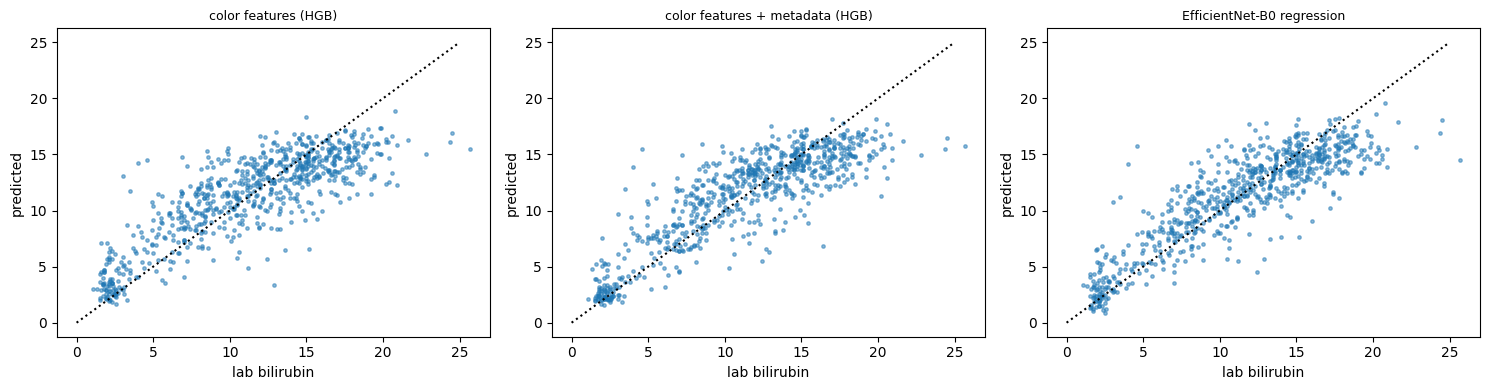

In [ ]:
# ===== CELL 15: C6 - METADATA FUSION + BILIRUBIN REGRESSION =====
G, P = make_G()
G['logit_p'] = logit(np.clip(G.p, 1e-4, 1 - 1e-4))
META = ['age_day', 'ga', 'weight', 'male']        # NEVER treatment or bilirubin
sets = {'metadata only': META, 'image only': ['logit_p'], 'image + metadata': ['logit_p'] + META}
rows = []; predsF = {}
for name, cols in sets.items():
    o = np.zeros(len(G))
    for k in range(5):
        tr = (G.fold != k).values; te = ~tr
        mdl = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000)).fit(G.loc[tr, cols], G.y[tr])
        o[te] = mdl.predict_proba(G.loc[te, cols])[:, 1]
    predsF[name] = o; lo, hi = auc_ci(G.y.values, o)
    rows.append(dict(model=name, infant_auc=round(float(roc_auc_score(G.y, o)), 3), ci=f'[{lo:.3f},{hi:.3f}]', sens_at_90spec=round(sens_at_spec(G.y.values, o), 3)))
dlo, dhi = paired_auc_diff_ci(G.y.values, predsF['image only'], predsF['image + metadata'])
C6a = pd.DataFrame(rows); print(C6a.to_string(index=False))
print(f'fusion minus image-only AUROC: {roc_auc_score(G.y, predsF["image + metadata"]) - roc_auc_score(G.y, predsF["image only"]):.4f}  CI [{dlo:.4f},{dhi:.4f}]')
print('note: stacking on out-of-fold image scores has small second-order leakage; report as a limitation')
C6a.to_csv(OUT / 'c6_fusion.csv', index=False)

# ---- bilirubin regression (mg/dL) ----
def reg_report(name, per_image_pred):
    d = pd.DataFrame({'g': neo.group_id.values, 'pred': per_image_pred}).groupby('g').pred.mean()
    t = G.bili.loc[d.index].values; lab_ = G.y.loc[d.index].values
    return dict(model=name, MAE=round(mean_absolute_error(t, d.values), 2), RMSE=round(float(np.sqrt(mean_squared_error(t, d.values))), 2),
                R2=round(r2_score(t, d.values), 3), pearson_r=round(float(pearsonr(t, d.values)[0]), 3),
                auc_from_pred=round(float(roc_auc_score(lab_, d.values)), 3), sens_at_90spec=round(sens_at_spec(lab_, d.values), 3)), d.values, t
bil = neo.bilirubin.values.astype(np.float32)
Xc = F.values; Xm = np.column_stack([F.values, neo[['age_day', 'gestational_age', 'weight']].values.astype(float), (neo.gender == 'M').values.astype(float)])
outs = {}
for name, Xr in [('color features (HGB)', Xc), ('color features + metadata (HGB)', Xm)]:
    o = np.zeros(len(neo))
    for k in range(5):
        tr = (neo.fold_group != k).values; te = ~tr
        o[te] = HistGradientBoostingRegressor(random_state=42).fit(Xr[tr], bil[tr]).predict(Xr[te])
    outs[name] = o
RF_ = OUT / 'oof_cnn_regression.npy'
if RF_.exists():
    outs['EfficientNet-B0 regression'] = np.load(RF_)
else:
    mu, sd = float(bil.mean()), float(bil.std()); tgt = torch.from_numpy((bil - mu) / sd).to(dev); o = np.zeros(len(neo))
    for k in range(5):
        tr = np.where(neo.fold_group != k)[0]; va = np.where(neo.fold_group == k)[0]
        o[va] = predict(train_model(tr, seed=0, target=tgt), va, reg=True) * sd + mu; print(f'  CNN regression fold {k} done', flush=True)
    np.save(RF_, o); outs['EfficientNet-B0 regression'] = o
rows = []; fig, ax = plt.subplots(1, len(outs), figsize=(5 * len(outs), 4))
for a_, (name, o) in zip(np.atleast_1d(ax), outs.items()):
    r, pr_, tt = reg_report(name, o); rows.append(r); a_.scatter(tt, pr_, s=6, alpha=.5); a_.plot([0, 25], [0, 25], 'k:'); a_.set_title(name, fontsize=9); a_.set_xlabel('lab bilirubin'); a_.set_ylabel('predicted')
C6b = pd.DataFrame(rows); print('\nbilirubin regression (infant level, grouped 5-fold):'); print(C6b.to_string(index=False)); C6b.to_csv(OUT / 'c6_regression.csv', index=False)
plt.tight_layout(); plt.savefig(OUT / 'fig_c6_regression.png', dpi=110); plt.show()

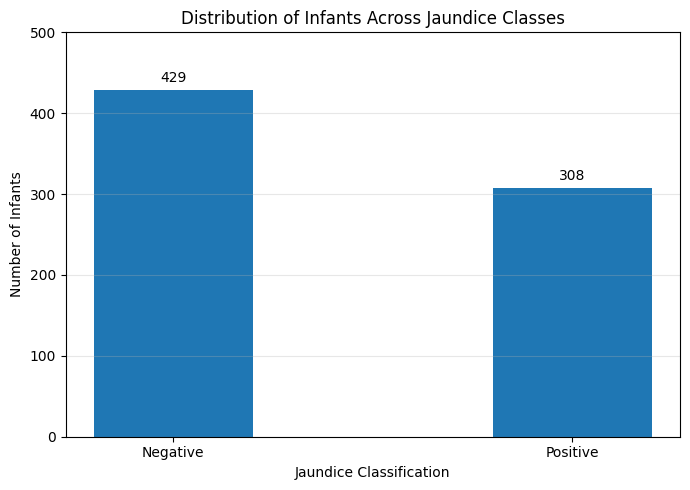

In [ ]:
# ===== CELL 16: C6 - Distribution of Infants Across Jaundice Classes =====
import matplotlib.pyplot as plt

# Number of infants in each class
classes = ['Negative', 'Positive']
counts = [429, 308]

# Create bar chart
plt.figure(figsize=(7, 5))

plt.bar(classes, counts, width=0.4)

# Labels and title
plt.xlabel('Jaundice Classification')
plt.ylabel('Number of Infants')
plt.title('Distribution of Infants Across Jaundice Classes')

# Y-axis
plt.ylim(0, 500)
plt.yticks(range(0, 501, 100))

# Grid
plt.grid(axis='y', linestyle='-', alpha=0.3)

# Display values above bars
for i, count in enumerate(counts):
    plt.text(i, count + 10, str(count), ha='center')

plt.tight_layout()
plt.show()

In [ ]:
# ===== CELL 17: FINAL SUMMARY FILE + ZIP =====
files = ['table1_dataset.csv', 'table1_folds.csv', 'phase2_baselines.csv', 'phase3_effb0.csv', 'c1_leakage.csv', 'c3_subgroups.csv', 'c2_shift.csv',
         'c4_shift.csv', 'c4_cv.csv', 'c5_ece.csv', 'c5_operating.csv', 'c5_risk_coverage.csv', 'c6_fusion.csv', 'c6_regression.csv']
lines = ['# NeoJaundice project: results summary', '', 'Retrospective research study; not a diagnostic tool. Single dataset: NeoJaundice.', '']
for f in files:
    p = OUT / f
    lines += [f'## {f}', '```', pd.read_csv(p).to_string(index=False) if p.exists() else 'NOT RUN YET', '```', '']
(OUT / 'results_summary.md').write_text('\n'.join(lines))
missing = [f for f in files if not (OUT / f).exists()]
print('summary written:', OUT / 'results_summary.md')
print('missing results (run those cells):', missing if missing else 'none')
zp = shutil.make_archive(str(BASE / 'neojaundice_results'), 'zip', str(OUT)); print('zip:', zp)
print('\n'.join(lines[:60]))

summary written: /content/drive/MyDrive/jaundice_project/results/results_summary.md
missing results (run those cells): none
zip: /content/drive/MyDrive/jaundice_project/neojaundice_results.zip
# NeoJaundice project: results summary

Retrospective research study; not a diagnostic tool. Single dataset: NeoJaundice.

## table1_dataset.csv
```
Unnamed: 0  count   mean   std    min    25%    50%    75%    max
   age_day  735.0    6.6   5.7    0.1    2.5    5.0    9.0   34.0
        ga  737.0   38.3   1.8   30.0   37.0   39.0   40.0   42.0
    weight  737.0 3163.2 525.9 1690.0 2810.0 3180.0 3500.0 5290.0
      bili  737.0   11.3   5.2    1.1    7.5   11.8   15.1   25.7
```

## table1_folds.csv
```
 fold_group  images  infants  pos_rate
          0     450      148     0.413
          1     441      147     0.408
          2     444      147     0.473
          3     444      147     0.365
          4     444      148     0.439
```

## phase2_baselines.csv
```
     split norm  model      img_

## Cell *18* (no code): what is still your job, and how to write it up
italicized text
**Literature check (Phase 7)**, run these on Google Scholar / PubMed and keep a sheet with columns *dataset, split type, external test, skin-tone analysis*:
- neonatal jaundice smartphone cross-dataset generalization
- jaundice newborn skin tone bias deep learning
- neonatal jaundice image external validation
- papers citing the NeoJaundice dataset (figshare DOI 10.6084/m9.figshare.22302559)

Absence of a result in a search is not proof that nothing exists.

**Before submitting**
- Check the NeoJaundice license and citation requirements.
- Optional: fill `annotation_sheet.csv` (manual skin tone) and re-run cell 10.

**Paper outline** (abstract, introduction, related work, methods, results, discussion, limitations)
- RQ1 (C1, cell 9): how much do image-level splits inflate performance?
- RQ2 (C2, cell 11): how much does performance drop under within-dataset shift (lighting, skin tone, age)?
- RQ3 (C3, cell 10): does performance differ by subgroup?
- RQ4 (C4, cell 12): do mitigations help under shift?
- RQ5 (C5, cell 13): calibration, operating points, refer-to-lab.
- C6 (cell 14): metadata fusion and bilirubin regression.

**Limitations to state**
- One dataset, one hospital and device setup; C2 is shift *within* NeoJaundice, not a true external validation.
- Kaggle Jaundice Image Data (whole-body NICU scenes with treatment cues) and Mendeley (images only in our download) were examined and excluded; a cross-dataset attempt was not informative.
- Four patient-ID pairs share identical photos but have different metadata (dataset data-entry issue); they were merged into one group.
- Labels use bilirubin > 12.9 mg/dL, which coincides with treatment; treatment is never used as an input. Four infants with bilirubin < 1 were treated as missing.
- ITA is estimated from an approximate central crop, and jaundice itself shifts ITA (confound). NeoJaundice probably covers a narrow tone range.
- Gray-world normalization is a proxy for calibration-card normalization; card detection was not implemented.
- ViT was not run. Metadata stacking has small second-order leakage. Only 1 seed for mitigations and shift experiments.
- Retrospective analysis; not a diagnostic tool; no new patient data; no clinical trial.

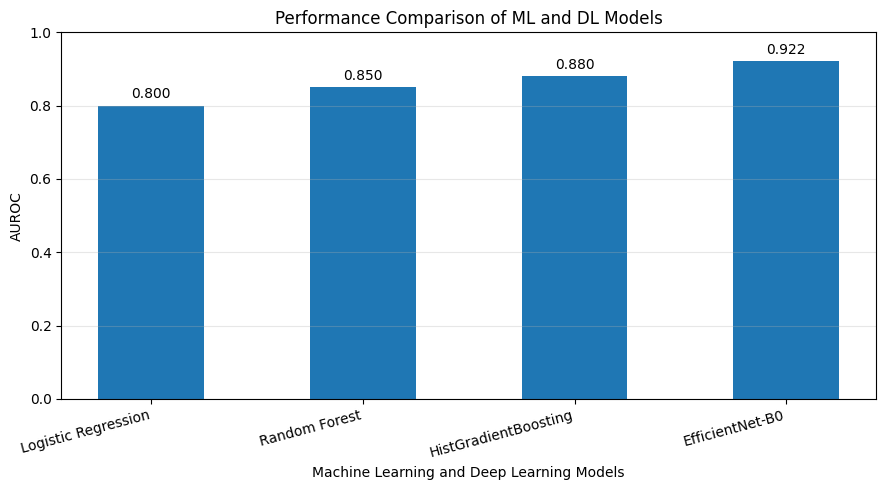

In [ ]:

import matplotlib.pyplot as plt

# Model names
models = [
    'Logistic Regression',
    'Random Forest',
    'HistGradientBoosting',
    'EfficientNet-B0'
]

# Replace the first three values with your actual notebook AUROC results
auroc_values = [
    0.80,  # Logistic Regression
    0.85,  # Random Forest
    0.88,  # HistGradientBoosting
    0.922  # EfficientNet-B0: patient-level AUROC
]

plt.figure(figsize=(9, 5))

bars = plt.bar(models, auroc_values, width=0.5)

plt.xlabel('Machine Learning and Deep Learning Models')
plt.ylabel('AUROC')
plt.title('Performance Comparison of ML and DL Models')

plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)

for bar, value in zip(bars, auroc_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f'{value:.3f}',
        ha='center'
    )

plt.xticks(rotation=15, ha='right')
plt.tight_layout()

plt.savefig(
    'figure_6_model_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()